In [1]:
from scipy import integrate

import index_function as index_function

from itertools import combinations

import networkx as nx
import scipy as scipy
import numpy as np
import matplotlib.pyplot as plt
from networkx.algorithms import bipartite
import random
import csv
import pandas as pd
import math
import importlib
import scienceplots
import pickle
from tqdm import tqdm
from matplotlib.ticker import MaxNLocator

import function_dynamics as fd
from scipy.integrate import odeint
from scipy import integrate
np.set_printoptions(threshold=100)
importlib.reload(index_function)
importlib.reload(fd)
from scipy.special import rel_entr

In [2]:
def collective_influence(G, l=2):
    """
    计算networkx图G中所有节点的Collective Influence (CI)。
    
    参数：
        G : networkx.Graph
            输入无向图
        l : int
            邻域半径
    
    返回：
        ci_dict : dict
            节点 -> CI值的字典
    """
    ci_dict = {}
    
    for node in G.nodes():
        k_i = G.degree(node)
        
        # 找到正好距离l的节点
        l_hop_neighbors = []
        for neighbor, dist in nx.single_source_shortest_path_length(G, node, cutoff=l).items():
            if dist == l:
                l_hop_neighbors.append(neighbor)
        
        sum_kj_minus1 = sum(G.degree(j) - 1 for j in l_hop_neighbors)
        ci = (k_i - 1) * sum_kj_minus1
        
        ci_dict[node] = ci
    
    return ci_dict

def index_value(graph):
    BNC = index_function.regular_betweeness_centrality(graph)
    CNC = index_function.regular_coreness(graph)
    
    EVC = index_function.regular_eigenector_centrality(graph)
    PRC = index_function.regular_page_rank(graph)
    CI = collective_influence(graph)

    katz = index_function.regular_katz_centrality(graph)

    CC = index_function.regular_closeness_centrality(graph)
    

    

    index_result = [BNC, CNC, EVC, PRC, CI, katz, CC]
    return index_result

In [3]:
from joblib import Parallel, delayed
import numpy as np
from tqdm import tqdm

def single_run_wrapper(evc, ci, bnc, degree, knn,prc, katz, cc, num):
    selected_indices = select_representatives_by_n(np.array(list(evc.values())), num)
    selected_indices1 = select_representatives_by_n(np.array(list(ci.values())), num)
    selected_indices2 = select_representatives_by_n(np.array(list(bnc.values())), num)
    selected_indices3 = select_representatives_by_n(np.array(list(degree.values())), num)
    selected_indices4 = select_representatives_by_n(np.array(list(knn.values())), num)

    selected_indices5 = select_representatives_by_n(np.array(list(prc.values())), num)
    selected_indices6 = select_representatives_by_n(np.array(list(katz.values())), num)
    selected_indices7 = select_representatives_by_n(np.array(list(cc.values())), num)
    

    # selected_indices = new_selected(evc, G, num)
    # selected_indices1 = new_selected(prc,G, num)
    # selected_indices2 = new_selected(bnc,G, num)
    # selected_indices3 = new_selected(degree,G, num)
    # selected_indices4 = new_selected(knn,G, num)
    

    return (
        selected_indices,
        selected_indices1,
        selected_indices2,
        selected_indices3,
        selected_indices4,
        selected_indices5,
        selected_indices6,
        selected_indices7)

def select_representatives_by_n(x, n):
    """
    把x按n个分位区间划分，从每个区间选择最接近区间均值的元素，返回这些元素在原数组中的索引。

    参数：
    x: array-like，一维数组
    n: int，划分区间数
    
    返回：
    indices: list，所选元素在原数组中的索引
    """
    x = np.asarray(x)
    # threshold = np.percentile(x, 95)
    
    # # 去掉最大的5%
    # filtered_data = x[x <= threshold]
    # x = filtered_data

    # 计算n个均匀分位数划分点
    split_points = np.quantile(x, np.linspace(0, 1, n + 1))
    split_points = np.unique(split_points)

    # 防止边界问题
    # split_points[0] -= 1e-8
    # split_points[-1] += 1e-8

    # 打标签
    labels = pd.cut(x, bins=split_points, labels=False, include_lowest=True)

    indices = []
    for i in range(n):
        group_idx = np.where(labels == i)[0]
        if len(group_idx) == 0:
            indices.append(None)  # 当前区间没元素
        else:
            group = x[group_idx]
            mean_val = group.mean()
            closest_idx_in_group = np.argmin(np.abs(group - mean_val))
            # sorted_indices = np.argsort(np.abs(group - mean_val))
            # closest_idx_in_group = sorted_indices[:1]
            # distances = np.abs(group[:, None] - group[None, :])  # pairwise distance matrix
            # avg_dist = distances.mean(axis=1)
            # closest_idx_in_group = np.argmin(avg_dist)
            indices.append(group_idx[closest_idx_in_group])

    indices = [x for x in indices if x is not None]
    return indices

In [4]:
def one_network_stats_result_adaptive_num(graph_name,choice):
    filename1 = f"./data/graph_{graph_name}.pkl"
    
    with open(filename1, "rb") as f:
        G = pickle.load(f)
    avg_neighbor_deg = nx.average_neighbor_degree(G)
    degree = dict(G.degree())
    

    index_G = index_value(G)
    index_BNC = index_G[0]
    index_CNC = index_G[1]
    
    index_EVC = index_G[2]
    index_PRC = index_G[3]
    index_CI = index_G[4]

    index_katz = index_G[5]
    index_CC = index_G[6]


    if choice=='adaptive':
        num = 4*int(np.floor(np.log(G.number_of_nodes())))
    else:
        num = int(np.floor(choice*(G.number_of_nodes())))
    ind = single_run_wrapper(index_EVC, index_CI, index_BNC, degree, avg_neighbor_deg, index_PRC, index_katz, index_CC, num)
    return ind

In [5]:
def error(x1,x2):
    return np.sum((x1-x2)**2) /(len(x2)*np.sum(x2))

def one_network_stats_result_adaptive_num_err(dynamic, graph_name,index_set):
    filename1 = f"./data/graph_{graph_name}.pkl"
    filename2 = f"./data/{dynamic}/result_{graph_name}.pkl"
    
    with open(filename1, "rb") as f:
        G = pickle.load(f)

    with open(filename2, "rb") as f:
        result_G = pickle.load(f)
    weights = [result_G[i][3] for i in range(len(result_G))]

    result_matrix_G = np.zeros((G.number_of_nodes(),len(weights)))
    for i in range(len(weights)):
        result_matrix_G[:,i] = result_G[i][4]

    mean_y = np.mean(result_matrix_G, axis=0)

    random_size = len(index_set[graph_name])
    err = np.zeros((random_size,))
    index_set_temp = index_set[graph_name]
    for i in range(random_size):
        selected_indices = index_set_temp[i]
        y = np.mean(result_matrix_G[selected_indices, :], axis=0)
        err[i] = error(y, mean_y)
    df = pd.DataFrame({
    'EVC': np.array([err[0]]),
    'CI': np.array([err[1]]),
    'BNC': np.array([err[2]]),
    'degree': np.array([err[3]]),
    'knn': np.array([err[4]]),
    'PRC': np.array([err[5]]),
    # 'Katz': np.array([err[6]]),
    'CC': np.array([err[7]])
    })
    return df

In [6]:
def one_network_stats_result_adaptive_num_err_random(dynamic, graph_name,index_set, random_name):
    filename1 = f"./data/graph_{graph_name}.pkl"
    filename2 = f"./data/{dynamic}/result_{graph_name}_{random_name}.pkl"
    
    with open(filename1, "rb") as f:
        G = pickle.load(f)

    with open(filename2, "rb") as f:
        result_G = pickle.load(f)
    weights = [result_G[i][3] for i in range(len(result_G))]

    result_matrix_G = np.zeros((G.number_of_nodes(),len(weights)))
    for i in range(len(weights)):
        result_matrix_G[:,i] = result_G[i][4]

    mean_y = np.mean(result_matrix_G, axis=0)

    random_size = len(index_set[graph_name])
    err = np.zeros((random_size,))
    index_set_temp = index_set[graph_name]
    for i in range(random_size):
        selected_indices = index_set_temp[i]
        y = np.mean(result_matrix_G[selected_indices, :], axis=0)
        err[i] = error(y, mean_y)
    df = pd.DataFrame({
    'EVC': np.array([err[0]]),
    'CI': np.array([err[1]]),
    'BNC': np.array([err[2]]),
    'degree': np.array([err[3]]),
    'knn': np.array([err[4]]),
    'PRC': np.array([err[5]]),
    # 'Katz': np.array([err[6]]),
    'CC': np.array([err[7]])
    })
    return df

In [7]:
name = [ "arenas_email", "FlyBi", "usair"] # , "arenas_email", "celegans_metabolic", "usair","BA_1000_2_2", "ER_1000_005", "ER_1000_010", "ER_1000_015",

In [8]:
all_adaptive_index = dict()
for graph_name in name:
    all_adaptive_index[graph_name] =  one_network_stats_result_adaptive_num(graph_name,'adaptive')

regular_betweeness_centrality
regular_coreness
regular_eigenector_centrality
regular_betweeness_centrality
regular_coreness
regular_eigenector_centrality
regular_betweeness_centrality
regular_coreness
regular_eigenector_centrality


In [9]:
sis_error = dict()
for graph_name in name:
    sis_error[graph_name] = one_network_stats_result_adaptive_num_err('sis', graph_name, all_adaptive_index) # 

In [11]:
name = [ "arenas_email", "FlyBi", "usair"]
double_well_error = dict()
for graph_name in name:
    double_well_error[graph_name] = one_network_stats_result_adaptive_num_err('double_well', graph_name, all_adaptive_index) # 

In [12]:
name = [ "arenas_email", "FlyBi", "usair"]
grn_error = dict()
for graph_name in name:
    grn_error[graph_name] = one_network_stats_result_adaptive_num_err('grn', graph_name, all_adaptive_index) # 

In [13]:
name = [ "arenas_email", "FlyBi", "usair"]
neuronal_error = dict()
for graph_name in name:
    neuronal_error[graph_name] = one_network_stats_result_adaptive_num_err('neuronal', graph_name, all_adaptive_index) # 

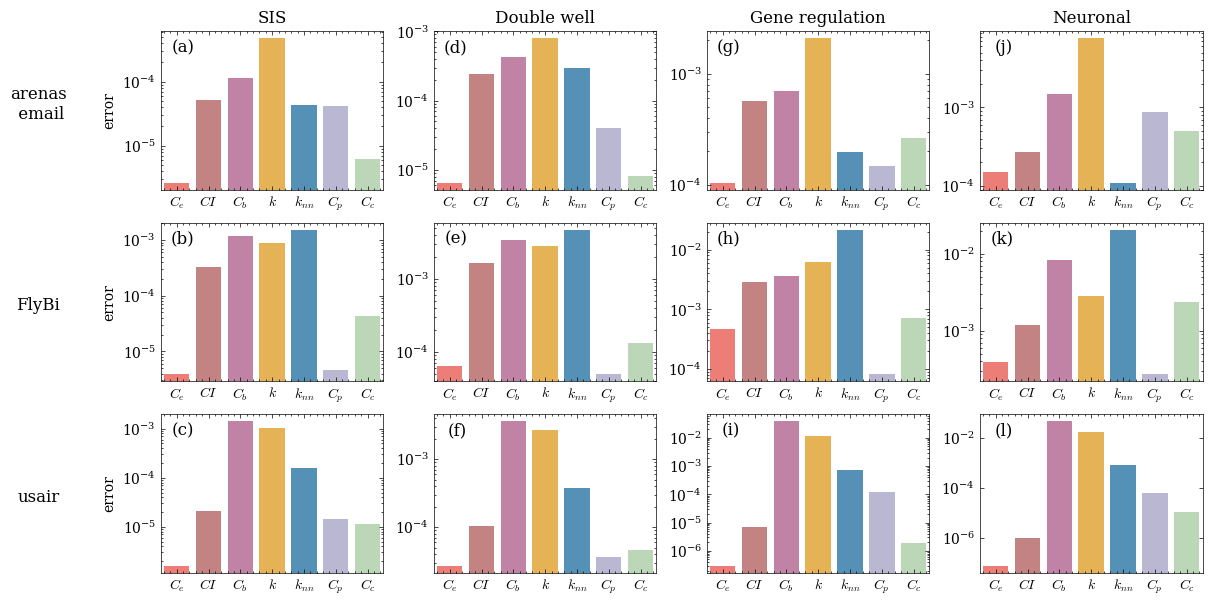

In [14]:
import seaborn as sns
import string
custom_colors = ['#FF6B64', '#CF7878', '#CB79A6', '#FEB83E',  '#4493C8', '#B6B3D6', '#B8DBB3']
with plt.style.context(['science', 'no-latex']):
    fig, axs = plt.subplots(nrows=3, ncols=4, figsize=(12, 6))
    err_all = sis_error
    name_plot = ['arenas\n email', name[1], name[2]]
    new_labels = [r'$C_e$',r'$CI$',r'$C_b$',r'$k$',r'$k_{nn}$', r'$C_p$', r'$C_c$']
    for i in range(len(name)):
        axs[i,0].set_ylabel('error')
        axs[i,0].text(-0.55, 0.45, name_plot[i],transform=axs[i, 0].transAxes, fontsize=12, ha='center')
    for i in range(len(name)):
        sns.barplot(data=err_all[name[i]], ax=axs[i,0], palette=custom_colors)
        # sns.set_context("notebook", font_scale=0.8)
        
        axs[i,0].set_xticklabels(new_labels)
        axs[i,0].set_yscale('log')  # 将y轴改为对数坐标
        
        axs[i,0].text(0.15, 0.95, '(%s)' % string.ascii_lowercase[i], transform=axs[i,0].transAxes,ha='right', va='top', fontsize=12)
    
    axs[0,0].set_title('SIS')
    # axs[2,0].set_xlabel('Index')
    # axs[].suptitle('SIS dynamics '+ r'$(n = 2\lfloor \ln(N)  \rfloor)$')
    err_all = double_well_error
    for i in range(len(name)):
        sns.barplot(data=err_all[name[i]], ax=axs[i,1], palette=custom_colors)
        axs[i,1].set_yscale('log')  # 将y轴改为对数坐标
        
        axs[i,1].set_xticklabels(new_labels)
        axs[i,1].text(0.15, 0.95, '(%s)' % string.ascii_lowercase[3+i], transform=axs[i,1].transAxes,ha='right', va='top', fontsize=12)
        # axs[1,i].set_title('BoxPlot for ' + name[i])
        # axs[1,i].set_xlabel('Index')
    axs[0,1].set_title('Double well')
    # axs[2,1].set_xlabel('Index')
    
    err_all = grn_error
    for i in range(len(name)):
        sns.barplot(data=err_all[name[i]], ax=axs[i,2], palette=custom_colors)
        
        axs[i,2].set_xticklabels(new_labels)
        axs[i,2].set_yscale('log')  # 将y轴改为对数坐标
        axs[i,2].text(0.15, 0.95, '(%s)' % string.ascii_lowercase[6+i], transform=axs[i,2].transAxes,ha='right', va='top', fontsize=12)
        # axs[2,i].set_title('BoxPlot for ' + name[i])
        # axs[2,i].set_xlabel('Index')
    axs[0,2].set_title('Gene regulation')
    # axs[2,2].set_xlabel('Index')

    err_all = neuronal_error
    for i in range(len(name)):
        sns.barplot(data=err_all[name[i]], ax=axs[i,3], palette=custom_colors)
        
        axs[i,3].set_xticklabels(new_labels)
        axs[i,3].set_yscale('log')  # 将y轴改为对数坐标
        axs[i,3].text(0.15, 0.95, '(%s)' % string.ascii_lowercase[9+i], transform=axs[i,3].transAxes,ha='right', va='top', fontsize=12)
        # axs[2,i].set_title('BoxPlot for ' + name[i])
        
    axs[0,3].set_title('Neuronal')
    # axs[2,3].set_xlabel('Index')
    # plt.suptitle('Double well dynamics '+ r'$(n = 2\lfloor \ln(N)  \rfloor)$')
fig.tight_layout(pad=0.5)  # pad 越小，间距越小
# plt.savefig('./figure/Fig2-2_revised.pdf', dpi=300, bbox_inches='tight', transparent=True)
plt.show()